# 00 — Tổng quan và chất lượng dữ liệu Gold

Kiểm tra inventory, numeric coverage và các khoảng trống trước khi phân tích nghiệp vụ.

Environment: Windows host, Python 3.10–3.13; `pip install -r requirements/analytics.txt`.
Docker `tlcn-local` đã healthy, Windows available >=2 GiB, WSL >=3 GiB, không active writer/DagRun.
Không start Spark. Mỗi notebook chạy độc lập, theo thứ tự cells. Query names/typed filters hiển thị
trong retrieval cells; kết quả là full scoped results/aggregates, **không phải 20-row sample consumer**.
Source-scoped identities không phải official crosswalk. Không forward-fill/interpolate.

Chạy `python scripts/run_eda_notebooks.py --notebook <filename>` từ repo root để execute và cập nhật
Markdown diễn giải bằng đúng measured evidence. Kết quả Markdown ghi batch cố định bên trên;
publication đổi sẽ fail closed. Không dùng outputs cũ như live query cache.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/gold/consumer.py').exists())
sys.path.insert(0, str(ROOT/'src'))  # repository bootstrap, no credentials
import pandas as pd
import numpy as np
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from analytics.client import EDAClient
from analytics.methods import calendar_yoy, endpoint_change, monthly_calendar
from analytics.notebook import inspect_frame, label, resolve, annual_plot, save_evidence
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
client = EDAClient()
findings = []
inventory = client.query('publication')
EXPECTED_BATCH = 'ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235'
assert client.batch == EXPECTED_BATCH, 'Publication changed: review scope before reproducing EDA'
display(inventory)
print('Published batch:', client.batch, '| No query cache | Windows/WSL/writer gates checked per request')

,table,rows,uuid,snapshot_id
0,dim_date,2038,0d029553-197b-4e46-8d62-17f21334a11b,7665947661409225898
1,dim_month,800,4f262a83-5e36-4d9e-b7e0-18f91b46327f,8295574410069434036
2,dim_observation_type,34,8adc0a9f-498e-4503-aa05-f95ae5a358ed,1046146616745412073
3,dim_price_series,1042,fa39bf1e-bbf1-4b50-8129-de1d4f37413b,2896601742107309180
4,dim_source_geography,987,ce487b86-5541-44de-a006-365dfbcc29f2,8664595598201008097
5,dim_source_product,295,4ce4f42f-e876-4870-8b2a-0312c460d673,8514812747103222137
6,dim_source_system,9,3c9fdb0f-127a-45f4-8f5b-31c7d1d5c0c1,5212267582300439758
7,dim_year,67,032861f7-4c4e-4ac4-9a10-274670b1d694,3316235776078407392
8,fact_fao_price_annual,9993,3218dd14-0793-4c1d-941c-31ba5e1aaea8,6561274137596983252
9,fact_fao_production_observation,22738,f97e800f-ebe6-416c-918a-a148ec0388b4,4557995850181557281


Published batch: ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235 | No query cache | Windows/WSL/writer gates checked per request


## Câu hỏi 1 — Mỗi fact có bao nhiêu quan sát, NULL, zero và cảnh báo?

In [2]:
from analytics.queries import PERIODS
overview = pd.DataFrame([{'fact':fact, **client.query('fact_overview', fact=fact).iloc[0].to_dict()} for fact in PERIODS])

In [3]:
display(overview.shape, inspect_frame(overview), overview)

(9, 9)

,dtype,nulls
fact,object,0
rows,int64,0
numeric_observations,int64,0
missing_observations,int64,0
genuine_zero,int64,0
warned_observations,int64,0
first_period,int64,0
last_period,int64,0
represented_periods,int64,0


,fact,rows,numeric_observations,missing_observations,genuine_zero,warned_observations,first_period,last_period,represented_periods
0,fact_nso_observation,23060,22114,946,5,22534,1990,2024,35
1,fact_fao_production_observation,22738,22509,229,572,0,1961,2024,64
2,fact_fao_sua_observation,36380,36123,257,8660,236,2010,2023,14
3,fact_fao_trade_observation,1226470,1226470,0,133948,0,1986,2024,39
4,fact_usda_psd_observation,990,990,0,140,0,1960,2025,66
5,fact_price_monthly,61573,55168,6405,0,0,196001,202512,792
6,fact_fao_price_annual,9993,9993,0,2,0,1991,2025,35
7,fact_usda_price_reference,12936,8413,4523,0,0,1985,2025,41
8,fact_vn_market_quote_daily,20387,20387,0,29,29,20210104,20260803,1211


In [4]:
assert len(inventory)==17 and sum(inventory.table.str.startswith('dim_'))==8
assert not overview.fact.duplicated().any()
assert (overview.rows == overview.numeric_observations + overview.missing_observations).all()
expected=inventory.set_index('table')['rows']
assert all(row.rows==expected[row.fact] for row in overview.itertuples())

In [5]:
overview['missing_rate_pct']=100*overview.missing_observations/overview.rows
display(overview[['fact','rows','numeric_observations','missing_rate_pct','genuine_zero','warned_observations']])

,fact,rows,numeric_observations,missing_rate_pct,genuine_zero,warned_observations
0,fact_nso_observation,23060,22114,4.102342,5,22534
1,fact_fao_production_observation,22738,22509,1.007125,572,0
2,fact_fao_sua_observation,36380,36123,0.706432,8660,236
3,fact_fao_trade_observation,1226470,1226470,0.000000,133948,0
4,fact_usda_psd_observation,990,990,0.000000,140,0
5,fact_price_monthly,61573,55168,10.402287,0,0
6,fact_fao_price_annual,9993,9993,0.000000,2,0
7,fact_usda_price_reference,12936,8413,34.964440,0,0
8,fact_vn_market_quote_daily,20387,20387,0.000000,29,29


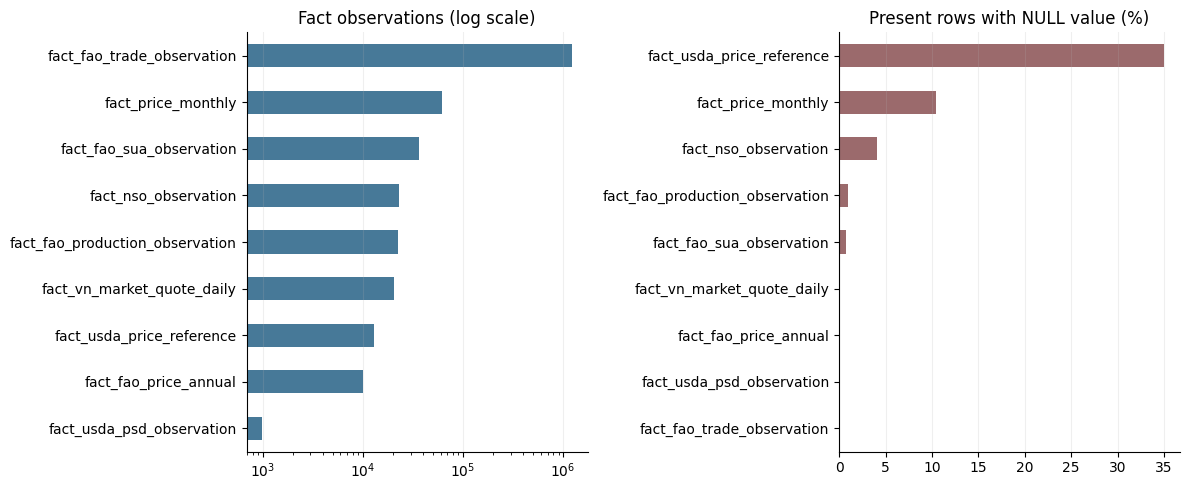

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
overview.set_index('fact').rows.sort_values().plot.barh(ax=axes[0],logx=True,color='#477998',title='Fact observations (log scale)')
overview.set_index('fact').missing_rate_pct.sort_values().plot.barh(ax=axes[1],color='#9b6a6c',title='Present rows with NULL value (%)')
for ax in axes: ax.set_ylabel('');ax.grid(axis='x',alpha=.2)
fig.tight_layout();plt.show();plt.close(fig)

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Hai chart đo quy mô và present-NULL, không xếp hạng độ tin cậy chỉ bằng số dòng.

In [7]:
total=int(overview.rows.sum())
most=overview.sort_values('missing_rate_pct',ascending=False).iloc[0]
findings.append(dict(id='OV01',title='Numeric coverage khác nhau giữa các subject areas',
 observation=f"9 facts có {total:,} observations. {most.fact} có {int(most.missing_observations):,}/{int(most.rows):,} present-NULL ({most.missing_rate_pct:.2f}%).",
 scope='All nine published facts; count(value)/count(*)', interpretation='NULL cần được giữ trong diagnostics; không thay bằng zero hoặc so missing rates như source quality scores.',
 query='fact_overview',cell='Câu hỏi 1',numbers=overview.to_dict(orient='records')))

## Câu hỏi 2 — Min/max có che khoảng trống thời gian không?

In [8]:
coverage={fact:client.query('period_coverage',fact=fact) for fact in PERIODS}
display({k:v.shape for k,v in coverage.items()})

{'fact_nso_observation': (35, 3),
 'fact_fao_production_observation': (64, 3),
 'fact_fao_sua_observation': (14, 3),
 'fact_fao_trade_observation': (39, 3),
 'fact_usda_psd_observation': (66, 3),
 'fact_price_monthly': (792, 3),
 'fact_fao_price_annual': (35, 3),
 'fact_usda_price_reference': (41, 3),
 'fact_vn_market_quote_daily': (1211, 3)}

In [9]:
gap_rows=[];year_rows=[]
for fact,df in coverage.items():
    assert not df.period.duplicated().any()
    observed=pd.Index(df.period.astype(int))
    kind=PERIODS[fact]
    if kind=='month_key':
        periods=pd.to_datetime(observed.astype(str),format='%Y%m').to_period('M')
        full=pd.period_range(periods.min(),periods.max(),freq='M')
        years=observed//100
    elif kind=='date_key':
        periods=pd.to_datetime(observed.astype(str),format='%Y%m%d')
        full=pd.date_range(periods.min(),periods.max(),freq='D')
        years=observed//10000
    else:
        periods=observed;full=pd.Index(range(observed.min(),observed.max()+1));years=observed
    gap_rows.append(dict(fact=fact,represented=len(periods),calendar_span=len(full),absent_periods=len(full.difference(periods))))
    year_rows += [dict(fact=fact,year=int(y)) for y in sorted(set(years))]
gaps=pd.DataFrame(gap_rows)
display(gaps)

,fact,represented,calendar_span,absent_periods
0,fact_nso_observation,35,35,0
1,fact_fao_production_observation,64,64,0
2,fact_fao_sua_observation,14,14,0
3,fact_fao_trade_observation,39,39,0
4,fact_usda_psd_observation,66,66,0
5,fact_price_monthly,792,792,0
6,fact_fao_price_annual,35,35,0
7,fact_usda_price_reference,41,41,0
8,fact_vn_market_quote_daily,1211,2038,827


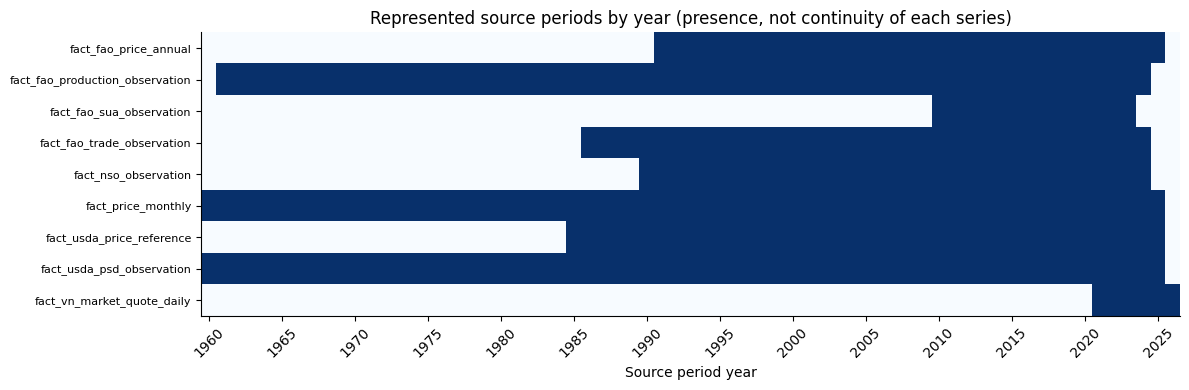

In [10]:
grid=pd.crosstab(pd.DataFrame(year_rows).fact,pd.DataFrame(year_rows).year).clip(upper=1)
fig,ax=plt.subplots(figsize=(12,4));ax.imshow(grid.values,aspect='auto',cmap='Blues',vmin=0,vmax=1)
ax.set_yticks(range(len(grid)),grid.index,fontsize=8)
ax.set_xticks(range(0,len(grid.columns),5),grid.columns[::5],rotation=45)
ax.set(title='Represented source periods by year (presence, not continuity of each series)',xlabel='Source period year')
fig.tight_layout();plt.show();plt.close(fig)

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Daily gaps có thể là ngày không báo giá; không tự coi đó là ingestion failure. Coverage toàn fact không chứng minh từng series liên tục.

In [11]:
findings.append(dict(id='OV02',title='Coverage được đếm bằng represented periods',
 observation='Các khoảng trống calendar đã được tính trực tiếp từ distinct periods; xem bảng số dưới đây.',
 scope='Global fact period domain, not individual series', interpretation='Trend metrics cần kiểm tra calendar gaps ở đúng series; không suy continuity từ min/max.',
 query='period_coverage',cell='Câu hỏi 2',numbers=gaps.to_dict(orient='records')))

## Câu hỏi 3 — Source identities, metric units và quality warnings nói gì?

In [12]:
geographies=client.query('catalogue',kind='geographies')
products=client.query('catalogue',kind='products')
metrics=client.query('catalogue',kind='metrics')
series=client.query('catalogue',kind='series')
nso_domain=client.query('nso_catalogue')
flags=client.query('context_profile',fact='fact_fao_production_observation',field='flag')
releases=client.query('context_profile',fact='fact_nso_observation',field='release_status')

In [13]:
display(geographies.groupby(['identity_namespace','source_level']).size().rename('members').to_frame())
display(products.groupby(['identity_namespace','identity_kind']).size().rename('members').to_frame())
display(metrics[['source_metric_id','gold_unit','aggregation_rule']])
display(series.groupby(['price_kind','unit','currency'],dropna=False).size().rename('series').to_frame())
display(nso_domain,flags,releases)

members
identity_namespace     source_level            
__technical__          not_applicable         1
faostat_m49            source_area          213
nso_raw_label          national              13
                       province             672
                       region                66
usda_psd_country       source_location        1
usda_yearbook_location source_location        4
vn_market_label        market_label          17

,,members
identity_namespace,identity_kind,
faostat_cpc,cpc_source_code,12
thitruongnongsan,market_commodity,195
usda_psd,source_commodity,1
usda_rice_yearbook,price_class,16
worldbank_pinksheet,benchmark,71


,source_metric_id,gold_unit,aggregation_rule
0,5610,tonne,AREA_OR_FLOW_NONOVERLAP
1,5922,USD,AREA_OR_FLOW_NONOVERLAP
2,Domestic Consumption,tonne,AREA_OR_FLOW_NONOVERLAP
3,Ending Stocks,tonne,NO_SUM_OVER_TIME
4,TY Imp. from U.S.,tonne,TY_SUBSET
5,Total Supply,tonne,NO_SUM_WITH_COMPONENTS
6,Yield,tonne/hectare,NEVER_SUM
7,Exports,tonne,MY_FLOW
8,Milling Rate (.9999),fraction,NEVER_SUM
9,Production,tonne,AREA_OR_FLOW_NONOVERLAP


series
price_kind            unit                 currency        
benchmark_price       USD/MMBtu            USD            3
                      USD/barrel           USD            4
                      USD/cubic_meter      USD            4
                      USD/dmtu             USD            1
                      USD/kg               USD           20
                      USD/tonne            USD           34
                      USD/troy_oz          USD            3
                      cents/sheet          NaN            1
index                 index(2010=100)      NaN            1
market_quote          VND/kg               VND          542
producer_price        LCU/tonne            LCU          103
                      SLC/tonne            SLC          101
                      USD/tonne            USD           98
producer_price_index  index(2014-2016=100) NaN           96
reported_export_price USD/tonne            USD           31

,source_table,measure,season,statistic_kind,source_level,unit,first_year,last_year,observations,numeric_observations,geographies
0,V06.13.csv,area,annual,quantity,province,hectare,1995,2024,1920,1876,64
1,V06.13.csv,area,annual,quantity,region,hectare,1995,2024,180,180,6
2,V06.14.csv,yield,annual,quantity,province,kg/hectare,1995,2024,1920,1876,64
3,V06.16.csv,area,winter_spring,quantity,province,hectare,1995,2024,1920,1863,64
4,V06.17.csv,yield,winter_spring,quantity,province,kg/hectare,1995,2024,1920,1863,64
5,V06.19.csv,area,summer_autumn_autumn_winter,quantity,region,hectare,1995,2024,120,120,4
6,V06.21.csv,production,summer_autumn_autumn_winter,quantity,province,tonne,1995,2024,960,908,32
7,V06.22.csv,area,main_season,quantity,province,hectare,1995,2024,1920,1758,64
8,V06.23.csv,yield,main_season,quantity,province,kg/hectare,1995,2024,1920,1758,64
9,V06.24.csv,production,main_season,quantity,region,tonne,1995,2024,180,180,6


,source_system_key,source_id,category,observations
0,4dd6194083c2858a1193dcb86d869577021c8304f06af3...,faostat_production,E,2787
1,4dd6194083c2858a1193dcb86d869577021c8304f06af3...,faostat_production,M,229
2,4dd6194083c2858a1193dcb86d869577021c8304f06af3...,faostat_production,A,18566
3,4dd6194083c2858a1193dcb86d869577021c8304f06af3...,faostat_production,I,673
4,4dd6194083c2858a1193dcb86d869577021c8304f06af3...,faostat_production,X,483


,source_system_key,source_id,category,observations
0,33c1890ba6d1525b73fa55c11ce2662624ec32f37e3a7a...,nso,unconfirmed,22294
1,33c1890ba6d1525b73fa55c11ce2662624ec32f37e3a7a...,nso,provisional,766


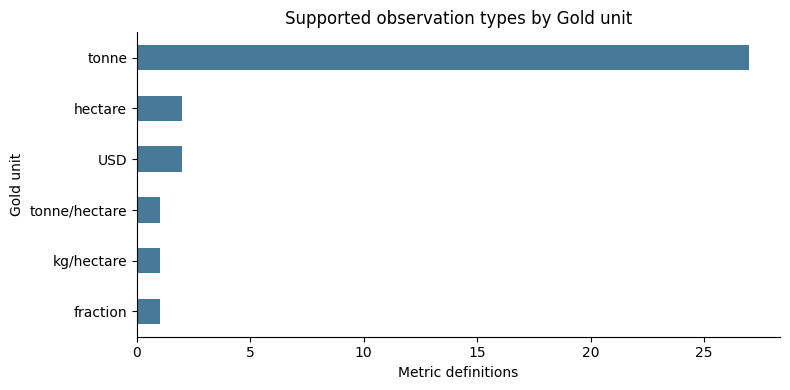

In [14]:
fig,ax=plt.subplots(figsize=(8,4));metrics.groupby('gold_unit').size().sort_values().plot.barh(ax=ax,color='#477998')
ax.set(title='Supported observation types by Gold unit',xlabel='Metric definitions',ylabel='Gold unit');fig.tight_layout();plt.show();plt.close(fig)

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Source flags và NSO release status là bằng chứng mô tả, không tự chuyển unconfirmed thành FINAL. Structural exclusions không thể suy ra từ retained Gold rows.

In [15]:
findings.append(dict(id='OV03',title='Units và identities chưa universally conformed',
 observation=f"Có {len(metrics)} metric definitions, {len(series)} price series và {geographies.identity_namespace.nunique()} geography namespaces trong inventory.",
 scope='Published dimensions',interpretation='NSO/FAO/USDA/price benchmarks cần filters riêng; ưu tiên production và từng price series có đủ numeric/calendar coverage.',
 query='catalogue',cell='Câu hỏi 3'))

## Key Findings

Measured batch `ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235`.

### OV01 — Numeric coverage khác nhau giữa các subject areas

**OBSERVATION:** 9 facts có 1,414,527 observations. fact_usda_price_reference có 4,523/12,936 present-NULL (34.96%).

**Scope:** All nine published facts; count(value)/count(*)

**INTERPRETATION / LIMITATION:** NULL cần được giữ trong diagnostics; không thay bằng zero hoặc so missing rates như source quality scores.

**Reproduce:** query `fact_overview`, Câu hỏi 1.

### OV02 — Coverage được đếm bằng represented periods

**OBSERVATION:** Các khoảng trống calendar đã được tính trực tiếp từ distinct periods; xem bảng số dưới đây.

**Scope:** Global fact period domain, not individual series

**INTERPRETATION / LIMITATION:** Trend metrics cần kiểm tra calendar gaps ở đúng series; không suy continuity từ min/max.

**Reproduce:** query `period_coverage`, Câu hỏi 2.

### OV03 — Units và identities chưa universally conformed

**OBSERVATION:** Có 34 metric definitions, 1042 price series và 6 geography namespaces trong inventory.

**Scope:** Published dimensions

**INTERPRETATION / LIMITATION:** NSO/FAO/USDA/price benchmarks cần filters riêng; ưu tiên production và từng price series có đủ numeric/calendar coverage.

**Reproduce:** query `catalogue`, Câu hỏi 3.

## Limitations

Row counts không chứng minh source quality. Không có official crosswalk, release vintages hay denominator của structural exclusions trong Gold retained facts.

In [16]:
print(save_evidence(ROOT, '00_gold_data_overview', client, findings))
print('Query audit:')
display(pd.DataFrame(client.evidence)[['query','row_count','query_seconds','response_bytes','batch']])

docs/analytics/evidence/00_gold_data_overview.json
Query audit:


,query,row_count,query_seconds,response_bytes,batch
0,publication,17,0.000000,4333,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
1,fact_overview,1,0.275262,3716,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
2,fact_overview,1,0.217779,3726,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
3,fact_overview,1,0.207220,3721,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
4,fact_overview,1,0.768189,3726,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
5,fact_overview,1,0.195768,3712,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
6,fact_overview,1,0.210644,3717,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
7,fact_overview,1,0.130951,3708,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
8,fact_overview,1,0.145403,3717,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
9,fact_overview,1,0.096412,3727,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
